# Experimental: lateral continuity between traces

Delivery inverts every trace on its own. On the 200-trace wedge of
`synthetic_wedge.ipynb` this leaves vertical striping in the estimated
impedance: seismic constrains impedance *contrasts* well but absolute levels
poorly, so each trace's absolute shale impedance wanders within its prior
range independently of its neighbours.

Deterministic inversions fix this with spatial regularisation. For example
`pylops.avo.poststack.PoststackInversion(..., epsR=...)` solves all traces at
once with a Laplacian penalty on differences between neighbouring traces. A
Bayesian sampler like Delivery cannot simply add a penalty: it needs a prior
that says *how similar* neighbouring traces are expected to be.

This notebook tries that, with **`pydelivery.lateral`** (experimental).

**The prior.** At every trace each rock property keeps exactly Delivery's
prior (its trend-curve mean ± scatter). What is added is correlation along
the line: a property's deviation from its trend is correlated between
traces, decaying with distance over a **correlation length** `L` (in traces,
like the range of a variogram). Neighbours are then similar and distant
traces independent. `L → 0` is ordinary Delivery.

**What is coupled.** Rock properties: shale vp, vs, density; sand vp, vs,
porosity; net-to-gross. Layer times are not coupled, so the wedge geometry is
left to the seismic. Fluid states and pinch-outs are not coupled either:
they stay per trace.

**How it is computed** (one extra pass, all in parallel):

1. Invert every trace on its own.
2. Summarise what each trace's data say about the coupled properties (its
   posterior divided by its prior, as Gaussians).
3. Run a Kalman smoother along the line: for each trace this gives the
   information arriving from all *other* traces' data through the
   correlation, without counting anything twice.
4. Re-invert every trace with that information as one extra prior term.

We compare: trace-by-trace (`L = 0`), a short correlation (`L = 10` traces)
and a long one (`L = 50`). The run takes about 13 minutes on four cores.

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pydelivery import Inversion
from pydelivery.describe import show
from pydelivery.lateral import LateralCoupling, invert_lateral
from pydelivery.qc import plot_qc, posterior_sections

sys.path.insert(0, ".")
from wedge_example import build_wedge   # same data as synthetic_wedge.ipynb

work = Path("lateral_data")
truth = build_wedge(work)
x, times, data, Z_true = truth["x"], truth["times"], truth["data"], truth["Z_true"]
inv = Inversion.from_files(work / "ModelDescription.xml", work / "priors.h5")
show(inv.cfg, groups=["trends", "implied"]);

,type,vp (m/s),vs (m/s),density / porosity,grain & reference fluid
rock,,,,,
sand,reservoir,3000 ± 150,-733 + 0.768·vp ± 100,porosity = 0.655 - 0.0001183·vp ± 0.02,"grains vp 6110, vs 4131, rho 2649; reference fluid brine"
shale,non-reservoir,2812 ± 100,-496 + 0.57·vp ± 43,density = 300·vp^0.26 ± 20,-


The trend table is where the lateral prior gets its scale: shale vp may
differ from the trend by ±100 m/s at any trace. The coupling only says how
that deviation is *correlated* between traces.

## Step 1: trace-by-trace (ordinary Delivery)

In [2]:
start = time.time()
base = inv.run(n_samples=500, seed=1, n_jobs=-1)
print(f"trace-by-trace: {time.time() - start:.0f} s")

trace-by-trace: 290 s


## Step 2: with lateral correlation

Both runs start from the trace-by-trace result and re-invert each trace once.
For each correlated property the code reports the implied standard deviation
of the difference between neighbouring traces: the quantity that plays the
role of pylops' `epsR`.

In [3]:
runs = {}
for L in (10, 50):
    start = time.time()
    runs[L] = invert_lateral(inv, LateralCoupling(correlation_length=L), n_samples=500,
                             seed=2, n_jobs=-1, start=base)
    print(f"L = {L:2d} traces: {time.time() - start:.0f} s")

r50 = runs[50]
print("\ncoupled variables:", [f"{name}(layer {layer + 1})" for name, layer in r50.keys])
pd.DataFrame({"prior sd at a trace": r50.prior_sd,
              "neighbour difference sd, L=10": runs[10].difference_sd,
              "neighbour difference sd, L=50": r50.difference_sd},
             index=[f"{n} (layer {l + 1})" for n, l in r50.keys]).round(4)

L = 10 traces: 250 s


L = 50 traces: 239 s

coupled variables: ['NG(layer 2)', 'phi_s(layer 2)', 'rho_m(layer 1)', 'rho_m(layer 2)', 'rho_m(layer 3)', 'vp_m(layer 1)', 'vp_m(layer 2)', 'vp_m(layer 3)', 'vp_s(layer 2)', 'vs_m(layer 1)', 'vs_m(layer 2)', 'vs_m(layer 3)', 'vs_s(layer 2)']


,prior sd at a trace,"neighbour difference sd, L=10","neighbour difference sd, L=50"
NG (layer 2),0.1000,0.0436,0.0199
phi_s (layer 2),0.0267,0.0117,0.0053
rho_m (layer 1),29.6351,12.9287,5.8975
rho_m (layer 2),29.6351,12.9287,5.8975
rho_m (layer 3),29.6351,12.9287,5.8975
vp_m (layer 1),100.0000,43.6263,19.9004
vp_m (layer 2),100.0000,43.6263,19.9004
vp_m (layer 3),100.0000,43.6263,19.9004
vp_s (layer 2),150.0000,65.4394,29.8506
vs_m (layer 1),71.4003,31.1493,14.2090


## Step 3: the impedance sections, with and without

The same QC panels as before, side by side: estimated impedance (posterior
mean) without and with the lateral prior, and the residual of each.

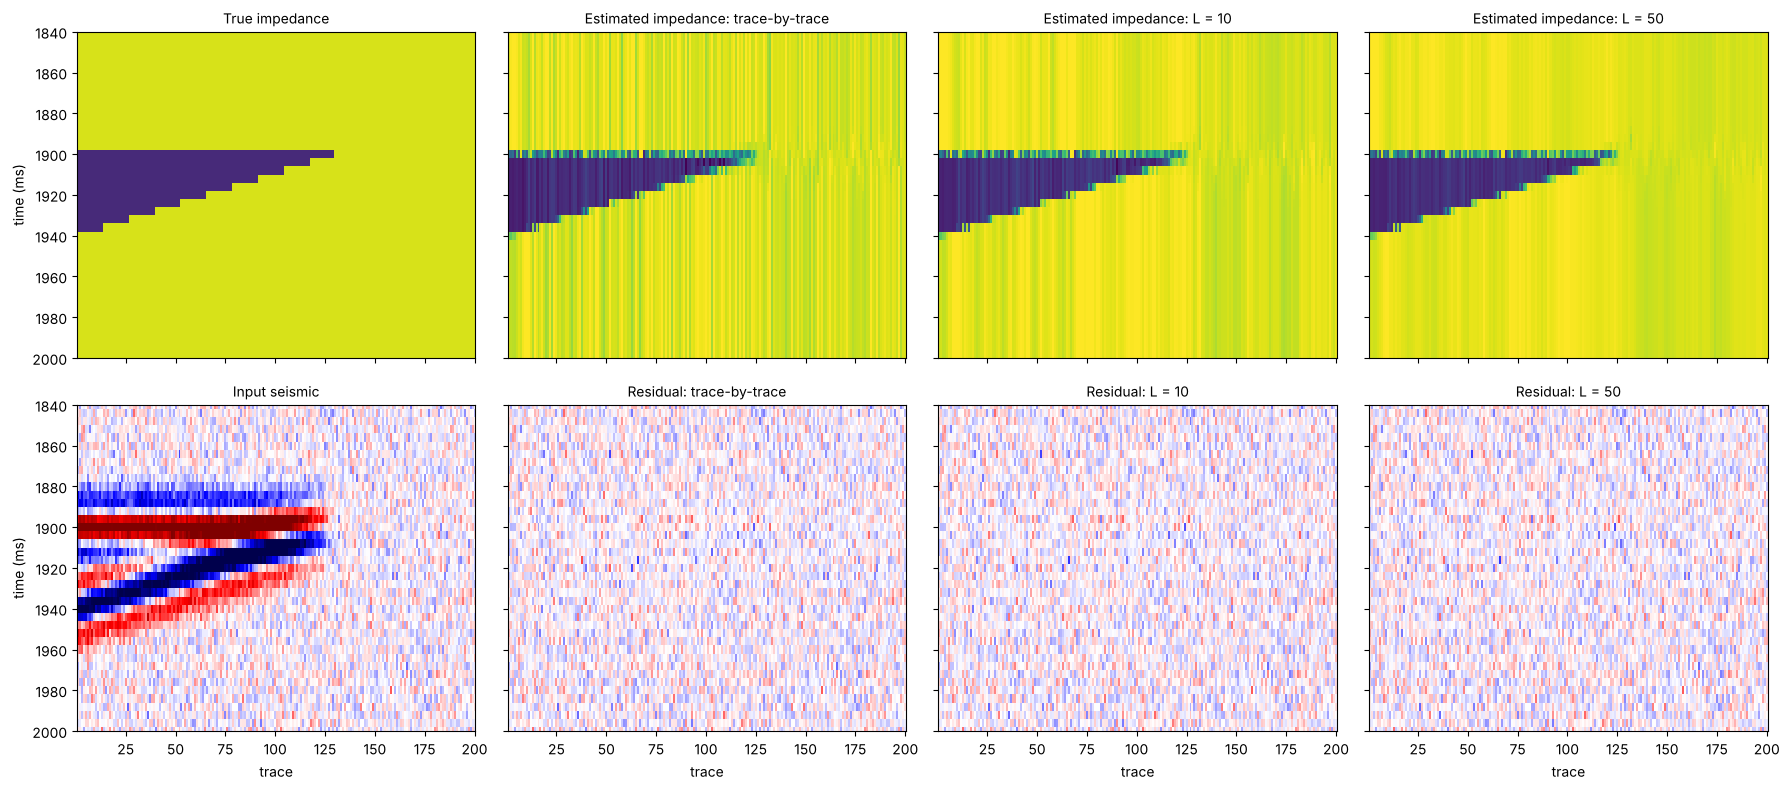

In [4]:
sections = {"trace-by-trace": posterior_sections(base, times)}
for L, run in runs.items():
    sections[f"L = {L}"] = posterior_sections(run.results, times)

zlo, zhi = np.percentile(Z_true, [1, 99]); zlo -= 2e5; zhi += 1e5
clip = np.percentile(np.abs(data), 99)
ext = [0.5, len(x) + 0.5, 1000 * times[-1] + 2, 1000 * times[0] - 2]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
order = [("True impedance", Z_true, "viridis", (zlo, zhi))] + \
        [(f"Estimated impedance: {n}", s["Zp_mean"], "viridis", (zlo, zhi)) for n, s in sections.items()] + \
        [("Input seismic", data, "seismic_r", (-clip, clip))] + \
        [(f"Residual: {n}", data - s["synthetic_mean"], "seismic_r", (-clip, clip)) for n, s in sections.items()]
for ax, (title, img, cmap, (lo, hi)) in zip(axes.ravel(), order):
    im = ax.imshow(img.T, aspect="auto", cmap=cmap, vmin=lo, vmax=hi, extent=ext, interpolation="nearest")
    ax.set_title(title, fontsize=10)
axes[0, 0].set_ylim(2000, 1840)
for ax in axes[:, 0]: ax.set_ylabel("time (ms)")
for ax in axes[1]: ax.set_xlabel("trace")
plt.tight_layout(); plt.show()

* **Striping** (top row): trace-by-trace, the shale impedance changes
  sharply from one trace to the next. With `L = 10` the needles merge into
  narrower bands; with `L = 50` what remains are broad, gentle bands. Those
  are long-wavelength variations of the absolute level, which the data still
  cannot pin down; they are much less distracting than trace-to-trace noise.
* **Wedge** (top row): its geometry is unchanged, because layer times are not
  coupled. The edge of the sand is as sharp as before.
* **Residuals** (bottom row): pure noise in all three cases. Coupling has not
  cost any fit to the seismic.

## Step 4: the numbers

A property-by-property comparison. *Jitter* is the typical change in the
posterior-mean impedance from one trace to the next (what shows as
striping). *Posterior sd* is the uncertainty at a trace. The residual and
misfit check that the data are still fitted, and the last columns check that
the geological answers are unchanged or better.

In [5]:
def summary(results, sec):
    Z = np.array([r.mean("Z_eff") for r in results])
    sd = np.array([r.std("Z_eff") for r in results])
    jitter = np.std(np.diff(Z, axis=0), axis=0) / np.sqrt(2)
    probs = np.array([r.fluid_probabilities()[1] for r in results])
    thick = np.array([1000 * np.median(r.samples["t"][:, 2] - r.samples["t"][:, 1]) for r in results])
    err = thick[:129] - 1000 * truth["thick_true"][:129]
    return {
        "seal jitter": jitter[0], "seal posterior sd": sd[:, 0].mean(),
        "base-shale jitter": jitter[2], "base-shale posterior sd": sd[:, 2].mean(),
        "residual RMS": np.sqrt(np.mean((data - sec["synthetic_mean"]) ** 2)),
        "normalised misfit": np.mean([r.samples["seismic_chisquare"].mean() for r in results]),
        "thickness error RMS (ms)": np.sqrt(np.mean(err ** 2)),
        "P(gas sand) traces 1-100": probs[:100, 4].mean(),
        "P(gas sand) traces 111-129": probs[110:129, 4].mean(),
        "P(no sand) traces 131-200": probs[130:, 0].mean(),
    }

table = pd.DataFrame({"trace-by-trace": summary(base, sections["trace-by-trace"]),
                      **{f"L = {L}": summary(run.results, sections[f"L = {L}"]) for L, run in runs.items()}})
table.style.format("{:.3g}")

,trace-by-trace,L = 10,L = 50
seal jitter,7.46e+04,2.93e+04,1.33e+04
seal posterior sd,2.29e+05,1.53e+05,1.01e+05
base-shale jitter,7.71e+04,2.71e+04,1.33e+04
base-shale posterior sd,2.28e+05,1.53e+05,1.02e+05
residual RMS,0.01,0.01,0.01
normalised misfit,0.971,0.967,0.967
thickness error RMS (ms),0.967,0.863,0.773
P(gas sand) traces 1-100,0.992,1,1
P(gas sand) traces 111-129,0.597,0.598,0.66
P(no sand) traces 131-200,0.717,0.691,0.648


* **Jitter** of the shale impedance falls from about 75,000 (trace-by-trace) to
  29,000 (`L = 10`) and 13,000 (`L = 50`): a factor of five or six.
* **Posterior sd** falls from about 229,000 to 153,000 and 101,000. This is
  genuine information: each trace now also learns from the seismic at its
  neighbours. The method is built so that no information appears without
  data (a test checks this).
* **Fit** is unchanged: residual RMS 0.010 (the noise added) and a normalised
  misfit just under 1 in every case.
* **Geology**: the sand thickness error falls from 0.97 ms to 0.77 ms; gas in
  the thick sand goes from 0.99 to 1.00 and in the thinning sand from 0.60 to
  0.66. Beyond the pinch-out the probability of no sand dips slightly (0.72 to
  0.65), with a little more weight on a thin brine sand; gas sand there stays
  at a few per cent.

## Step 5: one property along the line

Seal shale velocity (layer 1). The truth is the trend mean, 2812 m/s, at
every trace. Shaded bands are ± one posterior standard deviation.

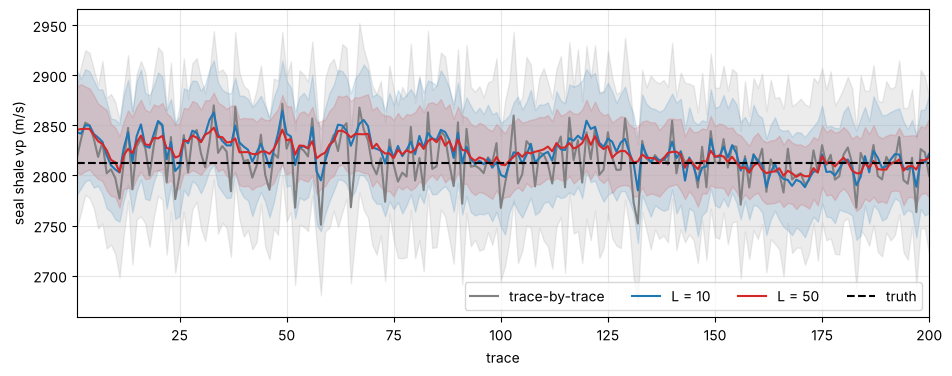

In [6]:
def vp_profile(results, key=("vp_m", 0)):
    mean, sd = [], []
    for r in results:
        v = np.array([r.vectors[i][r.modes[r.samples["mode"][i]].model.index[key]] for i in range(r.n_samples)])
        mean.append(v.mean()); sd.append(v.std())
    return np.array(mean), np.array(sd)

plt.figure(figsize=(11, 4))
for (name, results), colour in zip([("trace-by-trace", base), ("L = 10", runs[10].results),
                                    ("L = 50", runs[50].results)], ["gray", "tab:blue", "tab:red"]):
    m, s = vp_profile(results)
    plt.fill_between(x, m - s, m + s, color=colour, alpha=0.15)
    plt.plot(x, m, color=colour, label=name)
plt.axhline(2812, color="k", ls="--", label="truth")
plt.xlabel("trace"); plt.ylabel("seal shale vp (m/s)"); plt.xlim(1, len(x))
plt.legend(ncol=4); plt.grid(alpha=0.3); plt.show()

Trace-by-trace (grey), the estimate jumps around by tens of m/s from trace to
trace inside a wide band. With the lateral prior it becomes a smooth curve
with a narrower band. Note that the smooth curve is not exactly the truth:
over the left half it sits about 25-30 m/s above 2812 m/s, still inside its
±1 sd band. The seismic constrains impedance contrasts, so along a line it
can still drift slowly in absolute level. Smoothing removes the jitter; it
does not create absolute information that the data do not contain.

## Step 6: the geological answers

Pinch-out and fluid, with and without the lateral prior.

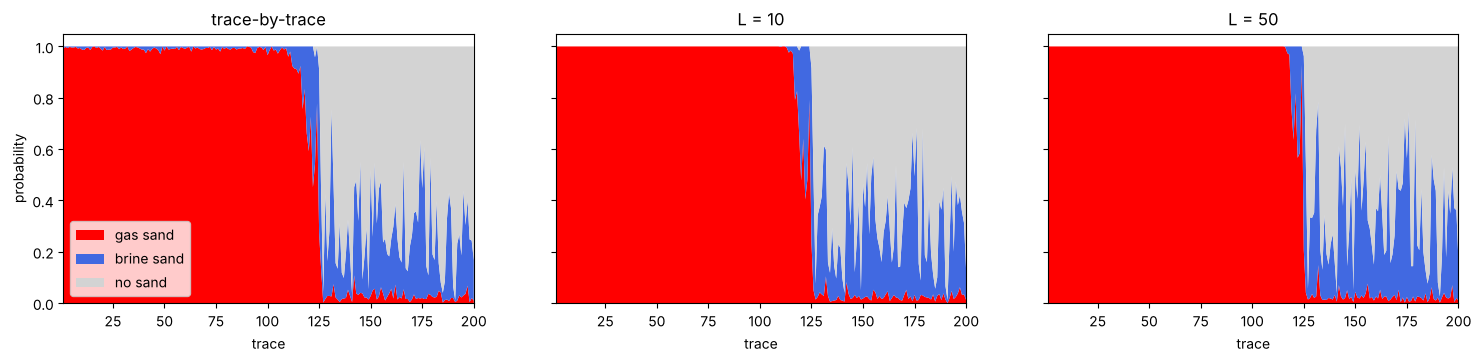

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.5), sharey=True)
for ax, (name, results) in zip(axes, [("trace-by-trace", base), ("L = 10", runs[10].results),
                                      ("L = 50", runs[50].results)]):
    p = np.array([r.fluid_probabilities()[1] for r in results])
    ax.stackplot(x, p[:, 4], p[:, 1], p[:, 0], colors=["red", "royalblue", "lightgray"],
                 labels=["gas sand", "brine sand", "no sand"])
    ax.set_title(name); ax.set_xlabel("trace"); ax.set_xlim(1, len(x))
axes[0].set_ylabel("probability"); axes[0].legend(loc="lower left"); plt.show()

Pinch-out and fluid answers are essentially unchanged, as they should be:
fluid states and pinch-outs are still decided trace by trace. Gas is slightly
cleaner just before the pinch-out (traces 110-125), because better-constrained
shale properties make the gas response easier to recognise.

## Step 7: does the jitter change the interpretation? (K-means facies QC)

An interpreter would eventually turn impedance into facies. A hard
classification shows whether the trace-to-trace jitter matters for that, or
is too small to change any label.

We classify every sample of the posterior-mean sections with **K-means** on
two features, P impedance and S impedance. Both are needed: brine sand and
shale have almost the same P impedance, but brine sand has a clearly higher
S impedance.

* **How many clusters?** One per facies the inversion says is present.
  Shale always counts. A sand facies (sand + a fluid) counts if it is the
  single most probable outcome for the reservoir layer at no fewer than 5 %
  of the traces. We also run the simpler question "gas sand or not", with two
  clusters.
* **Naming clusters**: each cluster is named after the nearest facies in the
  model's implied-properties table. Names are not forced to be unique. If
  two clusters both land nearest to shale, K-means has spent a cluster
  splitting the shale: a sign that something other than geology (here,
  jitter) is driving the classification.
* **Truth**: shale everywhere except the gas-sand wedge.

In [ ]:
from matplotlib.colors import ListedColormap
from pydelivery.qc import classify_facies, facies_present, model_facies

facies = model_facies(inv.cfg)
names = [f["name"] for f in facies]
SHALE, GAS = names.index("shale"), names.index("sand + gas")
win = (times >= 1.84) & (times <= 2.0)
tw = times[win]
true_lab = np.where((tw[None, :] >= truth["top_true"][:, None]) & (tw[None, :] < truth["base_true"][:, None]),
                    GAS, SHALE)

cases = {"trace-by-trace": (base, sections["trace-by-trace"]),
         "L = 10": (runs[10].results, sections["L = 10"]),
         "L = 50": (runs[50].results, sections["L = 50"])}

rows = []
for f in facies:
    row = {"facies": f["name"], "prior-mean Zp": f"{f['Zp']:.4g}", "prior-mean Zs": f"{f['Zs']:.4g}"}
    for name, (res, _) in cases.items():
        row[f"present? ({name})"] = f in facies_present(res, facies, layer=1)
    rows.append(row)
pd.DataFrame(rows).set_index("facies")

In [ ]:
def classify(sec, use):
    lab, centres, nearest = classify_facies(sec["Zp_mean"][:, win], sec["Zs_mean"][:, win], use)
    return np.array([facies.index(f) for f in use])[lab], centres, nearest

def scores(lab, n_clusters, nearest, use):
    same_truth = true_lab[1:] == true_lab[:-1]
    return {
        "clusters": n_clusters,
        "clusters named shale": int(sum(use[j]["name"] == "shale" for j in nearest)),
        "accuracy vs truth": (lab == true_lab).mean(),
        "true shale called sand": (lab[true_lab == SHALE] != SHALE).mean(),
        "true gas sand found": (lab[true_lab == GAS] == GAS).mean(),
        "label changes between neighbouring traces (where truth is unchanged)":
            (lab[1:] != lab[:-1])[same_truth].mean(),
    }

labels, table_rows = {}, {}
for name, (res, sec) in cases.items():
    use = facies_present(res, facies, layer=1)
    for tag, fs in ((f"{len(use)} classes (as determined)", use),
                    ("2 classes (gas sand or not)", [facies[SHALE], facies[GAS]])):
        lab, centres, nearest = classify(sec, fs)
        labels[(name, tag)] = (lab, centres, nearest, fs)
        table_rows[(tag, name)] = scores(lab, len(fs), nearest, fs)
pd.DataFrame(table_rows).style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else v)

In [ ]:
cmap = ListedColormap(["0.7", "royalblue", "red"])     # shale, brine sand, gas sand
tags = sorted({t for _, t in labels}, key=lambda t: t.startswith("2"))
ext = [0.5, len(x) + 0.5, 1000 * tw[-1] + 2, 1000 * tw[0] - 2]
fig, axes = plt.subplots(len(tags), 4, figsize=(18, 4 * len(tags)), sharex=True, sharey=True, squeeze=False)
for r, tag in enumerate(tags):
    axes[r, 0].imshow(true_lab.T, cmap=cmap, vmin=0, vmax=2, aspect="auto", extent=ext, interpolation="nearest")
    axes[r, 0].set_title("True facies"); axes[r, 0].set_ylabel(f"{tag}\ntime (ms)")
    for c, name in enumerate(cases, start=1):
        lab = labels[(name, tag)][0]
        axes[r, c].imshow(lab.T, cmap=cmap, vmin=0, vmax=2, aspect="auto", extent=ext, interpolation="nearest")
        axes[r, c].set_title(f"K-means: {name}")
for ax in axes[-1]: ax.set_xlabel("trace")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(j)) for j in range(3)]
fig.legend(handles, names, loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

The cross-plot shows why. Each point is one sample of the posterior-mean
section; colours are K-means clusters (with the determined number of
classes); stars are the facies' prior-mean impedances.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ["trace-by-trace", "L = 50"]):
    tag = next(t for (n, t) in labels if n == name and not t.startswith("2"))
    sec = cases[name][1]
    Zp, Zs = sec["Zp_mean"][:, win].ravel(), sec["Zs_mean"][:, win].ravel()
    X = np.column_stack([Zp, Zs]); scale = X.std(axis=0)
    lab, centres, nearest, fs = labels[(name, tag)]
    raw = np.argmin((((X[:, None, :] - centres[None]) / scale) ** 2).sum(-1), axis=1)
    for j in range(len(centres)):
        ax.scatter(Zp[raw == j] / 1e6, Zs[raw == j] / 1e6, s=2, alpha=0.4,
                   label=f"cluster {j + 1} -> {fs[nearest[j]]['name']}")
    for f, col in zip(facies, ["0.3", "royalblue", "red"]):
        ax.scatter(f["Zp"] / 1e6, f["Zs"] / 1e6, marker="*", s=300, color=col, edgecolor="k", zorder=5)
        ax.annotate(f["name"], (f["Zp"] / 1e6, f["Zs"] / 1e6), xytext=(6, 6), textcoords="offset points")
    ax.set_title(name); ax.set_xlabel("P impedance (x 1e6)"); ax.legend(markerscale=6, fontsize=8)
axes[0].set_ylabel("S impedance (x 1e6)"); plt.tight_layout(); plt.show()

KMEANS_TEXT

## Summary and caveats

* A correlated prior along the line removes most of Delivery's trace-to-trace
  striping (jitter down by a factor of five to six at `L = 50`), without
  costing any fit to the seismic and without changing the geometry, fluid or
  pinch-out answers. Thickness and thin-bed gas detection improve slightly.
* Unlike a deterministic Laplacian penalty, the result is still a posterior:
  uncertainty narrows only by what the neighbouring traces' data contribute,
  and the line-average level of a property is not claimed to be known better
  than the trend curves and the data allow.
* **Choosing `L`**: it is the distance over which rock properties stay
  similar, like the range of a variogram. Here the truth is constant along
  the line, so longer is better. In real data, take it from well
  correlations or the geology; too long a value would smooth over real
  lateral changes in rock properties.
* **Caveats** (this is experimental):
  - lines only (a 3-D grid needs loopy belief propagation);
  - each trace's information is summarised as a Gaussian, which suits rock
    properties but not fluids or pinch-outs (so those are not coupled);
  - the trend scatter is assumed the same along the line;
  - one extra pass doubles the run time.
* Layer times could be coupled the same way to smooth noisy horizon picks;
  that was left out here so the wedge geometry is decided by the seismic
  alone.